# What one streaming iteration spends before any data moves

`lsdb` can stream a HATS catalog partition-by-partition into a training loop
(`CatalogStream` / `InfiniteStream`). Every iteration, the library **constructs a fresh
Dask task graph for the next partition and ships it to the scheduler**. This notebook
measures what that costs, in two halves:

1. **Building** the graph — `Operation.build(pixels=[pixel])`, which walks the catalog's
   pixel list once per layer.
2. **Serializing** it — pickling the graph inside `client.compute()`, sending it, and the
   scheduler's `update_graph` handling on the far side.

Both are paid *per batch*, before a single byte of catalog data is read. Neither scales with
how much data the batch contains.

The headline: **which half dominates flips depending on catalog shape.** Building scales with
*partition count*; serializing scales with *schema width*. A wide catalog is bottlenecked on
serialization; a crossmatch over many partitions is bottlenecked on building. We measure both
axes and give the per-epoch cost for a realistic LSST workload.

*Standalone.* A companion notebook (`stream-hf-profile.ipynb`) covers the other side of the
loop — fetching, gathering, and shuffling the data itself, which dominates wall time for
wide-partition catalogs. Nothing here depends on having read it.

In [1]:
import cProfile
import io
import pickle
import platform
import pstats
import socket
import statistics as st
import sys
import warnings
from time import perf_counter

import dask
import matplotlib.pyplot as plt
import nested_pandas as npd
import numpy as np
import pandas as pd
from dask._expr import FinalizeCompute
from dask.base import collections_to_expr
from dask.delayed import Delayed
from distributed import Client, LocalCluster
from distributed.protocol import serialize, to_serialize

import lsdb
from lsdb.operations.lsdb_ops import FromHealpixMap

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "axes.titlesize": 16, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "figure.titlesize": 18,
})

print(f"host    {socket.gethostname()}")
print(f"python  {platform.python_version()}")
print(f"lsdb    {lsdb.__version__}")
print(f"        {lsdb.__file__}")   # the --user install, not any local checkout
print(f"dask    {dask.__version__}")

host    sdfiana032
python  3.13.13
lsdb    0.10.5.dev1+g36a32399e
        /sdf/home/o/olynn/.local/lib/python3.13/site-packages/lsdb/__init__.py
dask    2026.3.0


## 0. What the loop actually does each iteration

`CatalogIterator.__next__` gathers the pending future, shuffles the rows, then **builds and
submits the next chunk**. The submit path is `CatalogStream.submit_next_partitions`:

```python
def submit_next_partitions(self, partitions):
    def _to_delayed(operation, pixel):
        build = operation.build(pixels=[pixel])      # <-- rebuilt every iteration
        graph = build.graph
        key = build.pixel_to_key_map[pixel]
        return Delayed(key, graph)

    selected = [_to_delayed(self.operation, self._pixels[i]) for i in partitions]
    if len(selected) == 1:
        return self.client.compute(selected[0])      # <-- pickled + sent every iteration
    combined = dask.delayed(pd.concat)(selected)
    return self.client.compute(combined)
```

Two structural facts make this cost matter more than its size suggests:

- **Prefetch depth is exactly one.** `CatalogIterator` holds a single `self.future`. So
  `build → pickle → send → schedule → fetch → gather` is a fully serial chain per batch, with
  nothing to overlap it against. In a training loop, that latency is idle accelerator time.
- **It repeats per batch.** Cost multiplies by `npartitions / partitions_per_chunk` per epoch,
  and is completely independent of how many bytes each partition holds.

`client.compute()` is worth reading closely, because it does **not** do what its name suggests
in one place. From `distributed/client.py`:

```python
expr = expr.optimize()                                        # 1. optimize    (main thread)
...
expr_ser = Serialized(*serialize(to_serialize(expr), ...))    # 2. PICKLE      (main thread)
...
self._send_to_scheduler({"op": "update-graph", ...})          # 3. loop.add_callback -> returns
```

Step 3 enqueues onto the client's IO loop and returns *immediately*. **The wire send and the
scheduler's `update_graph` happen after `client.compute()` has already returned** — so timing
that call captures the pickle but not the delivery. We measure both sides separately in §3.

### Helpers

`pickle_stats` replicates exactly what `client.compute` does on the calling thread — the
optimize pass and the pickle — without sending anything. That makes it deterministic and
runnable with no cluster.

In [2]:
def op_chain(op):
    '''Operation layers, outermost first: 'MapPartitions<-SelectPixels<-FromHealpixMap'.'''
    names, o = [], op
    while True:
        names.append(type(o).__name__)
        if not o.dependencies:
            return "<-".join(names)
        o = o.dependencies[0]


def warm(op):
    '''Force the cached_property tokenization so timings measure build, not key_name.'''
    op.key_name, op.meta
    return op


def build_ms(op, n=20):
    '''Mean ms for one single-pixel build. Returns (ms, n_tasks_emitted).'''
    px = op.healpix_pixels
    warm(op)
    t0 = perf_counter()
    for k in range(n):
        g = op.build(pixels=[px[k % len(px)]])
    return 1e3 * (perf_counter() - t0) / n, len(g.graph)


def to_delayed(op, pixels):
    '''Exactly what submit_next_partitions assembles: one Delayed per pixel, concat if >1.'''
    parts = []
    for p in pixels:
        g = op.build(pixels=[p])
        parts.append(Delayed(g.pixel_to_key_map[p], g.graph))
    return parts[0] if len(parts) == 1 else dask.delayed(pd.concat)(parts)


def pickle_stats(target, n=5):
    '''client.compute()'s client-side work, minus the send. Returns (optimize_ms, pickle_ms, bytes).

    Bytes is the deterministic metric here; the ms figures move with machine load.
    '''
    t0 = perf_counter()
    expr = FinalizeCompute(collections_to_expr([target], True)).optimize()
    optimize_ms = 1e3 * (perf_counter() - t0)
    t0 = perf_counter()
    for _ in range(n):
        _, frames = serialize(to_serialize(expr), on_error="raise")
    return optimize_ms, 1e3 * (perf_counter() - t0) / n, sum(len(f) for f in frames)


def pbytes(obj):
    '''Pickled size of one object, or 0 if it will not pickle.'''
    try:
        return len(pickle.dumps(obj))
    except Exception:
        return 0


def walk_ops(op):
    '''Every Operation in the dependency tree, deduplicated by identity.'''
    seen, stack, out = set(), [op], []
    while stack:
        o = stack.pop()
        if id(o) in seen:
            continue
        seen.add(id(o))
        out.append(o)
        stack.extend(o.dependencies)
    return out


def constant_bytes(op):
    '''Pickled size of the per-iteration *constants* carried by a whole operation chain.

    Walks every layer, because a chain's constants do not all live on its outermost
    operation -- AlignAndApply (crossmatch) keeps its metas and schemas on the input
    operations underneath it. Objects are deduplicated by identity, since pickle memoizes
    a shared object within one call rather than writing it once per task.
    '''
    by_id = {}
    for o in walk_ops(op):
        for obj in (o.meta, getattr(o, "kwargs", {}).get("schema"),
                    getattr(o, "catalog_infos", None)):
            if obj is not None:
                by_id[id(obj)] = obj
    metas = {i: o for i, o in by_id.items() if isinstance(o, npd.NestedFrame)}
    return sum(pbytes(o) for o in metas.values()), sum(
        pbytes(o) for i, o in by_id.items() if i not in metas)

### The catalogs

Five configurations chosen to separate the two scaling axes — partition count and schema
width — plus one that loads both at once.

| config | source | probes |
|---|---|---|
| `dp2_dia_object` | DP2 at USDF | narrow + few partitions (control) |
| `dp2_object` | DP2 at USDF | **width** — 1,260 columns |
| `hf_legacysurvey` | Hugging Face | large bytes per partition |
| `hf_gaia` | Hugging Face | **partition count** — 33k partitions, 11 columns |
| `dp2_xmatch` | DP2 crossmatch | both — `AlignAndApply` over 121k output partitions |

`dp2_xmatch` is the workload this is really about: crossmatch two collections, then stream the
result into training.

In [3]:
DP2 = "/sdf/data/rubin/shared/lsdb_commissioning/hats/dp2/"
HF_LEGACY = "hf://datasets/UniverseTBD/mmu_ssl_legacysurvey_north/"
HF_GAIA = "hf://datasets/UniverseTBD/mmu_gaia_gaia@main/mmu_gaia_gaia"

catalogs = {}
t0 = perf_counter()
catalogs["dp2_dia_object"] = lsdb.open_catalog(DP2 + "dia_object")
catalogs["dp2_object"] = lsdb.open_catalog(DP2 + "object")
catalogs["hf_legacysurvey"] = lsdb.open_catalog(HF_LEGACY)
catalogs["hf_gaia"] = lsdb.open_catalog(HF_GAIA)

# The crossmatch: both collections carry a 5" margin cache, so this is a real one.
_dia_coll = lsdb.open_catalog(DP2 + "dia_object_collection")
_obj_coll = lsdb.open_catalog(DP2 + "object_collection")
catalogs["dp2_xmatch"] = _dia_coll.crossmatch(_obj_coll, radius_arcsec=1)
print(f"opened all in {perf_counter() - t0:.1f}s")

cat_info = pd.DataFrame([
    {"config": n, "npartitions": c.npartitions, "ncolumns": len(c.columns),
     "operations": op_chain(c._operation)}
    for n, c in catalogs.items()
]).set_index("config")
cat_info

opened all in 28.0s


,npartitions,ncolumns,operations
config,,,
dp2_dia_object,114,65,FromHealpixMap
dp2_object,5244,1260,FromHealpixMap
hf_legacysurvey,5488,15,FromHealpixMap
hf_gaia,33055,11,FromHealpixMap
dp2_xmatch,121551,43,AlignAndApply<-FromHealpixMap


## 1. Building the graph

`build(pixels=[p])` emits **one task per layer** — but to find that one pixel, every layer
walks the operation's *entire* pixel list. There are four such sites in
`lsdb/operations/lsdb_ops.py`:

| site | work done per single-pixel build |
|---|---|
| `FromHealpixMap.build` (:108) | scans all N pixels, `if pixel not in target: continue` — N `HealpixPixel.__hash__` calls |
| `MapPartitions.build` (:322) | rebuilds `{pixel: index}` over all N pixels — per layer, per build |
| `SelectPixels.build` (:411) | filters `self.pixels`, then `cull()` over the whole upstream graph |
| `AlignAndApply._resolve_build_subsets` (:509) | scans all output pixels; `cull()` again at :550 — the crossmatch path |

The source of the first, which is the one every catalog hits:

```python
def build(self, pixels=None):
    target = set(pixels) if pixels is not None else None
    graph = {}
    for i, pixel in enumerate(self.pixels):        # all N of them...
        if target is not None and pixel not in target:
            continue                              # ...to reject all but one
```

In [4]:
build_rows = []
for name, cat in catalogs.items():
    op = warm(cat._operation)
    ms, ntasks = build_ms(op)
    n = len(op.healpix_pixels)
    t0 = perf_counter()
    full = op.build()
    full_s = perf_counter() - t0
    build_rows.append({
        "config": name, "npartitions": n, "ncolumns": len(cat.columns),
        "tasks_per_build": ntasks, "build_1px_ms": ms,
        "full_build_s": full_s, "full_graph_nodes": len(full.graph),
        # what one full pass costs if built one pixel at a time, as the stream does
        "epoch_build_s": ms * n / 1e3,
        "vs_full_build": (ms * n / 1e3) / full_s,
    })
    del full

build_df = pd.DataFrame(build_rows).set_index("config")
build_df.round(3)

,npartitions,ncolumns,tasks_per_build,build_1px_ms,full_build_s,full_graph_nodes,epoch_build_s,vs_full_build
config,,,,,,,,
dp2_dia_object,114,65,1,0.027,0.000,114,0.003,6.543
dp2_object,5244,1260,1,0.838,0.027,5244,4.392,163.972
hf_legacysurvey,5488,15,1,0.855,0.024,5488,4.693,196.026
hf_gaia,33055,11,1,5.167,0.444,33055,170.804,384.955
dp2_xmatch,121551,43,4,57.141,4.559,370614,6945.503,1523.514


`build_1px_ms` tracks `npartitions`, not `ncolumns` — the defining signature of this half. The
`vs_full_build` column is the price of rebuilding per iteration instead of once.

In [5]:
# Confirm the mechanism directly: the hash calls should equal n_builds x npartitions.
op = warm(catalogs["hf_gaia"]._operation)
px = op.healpix_pixels
N_BUILDS = 20

pr = cProfile.Profile()
pr.enable()
for k in range(N_BUILDS):
    op.build(pixels=[px[k]])
pr.disable()

s = io.StringIO()
pstats.Stats(pr, stream=s).sort_stats("tottime").print_stats(6)
print(s.getvalue())
print(f"predicted __hash__ calls = {N_BUILDS} builds x {len(px):,} pixels = {N_BUILDS * len(px):,}")

         1323760 function calls (1323754 primitive calls) in 0.319 seconds

   Ordered by: internal time
   List reduced from 140 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
   661140    0.117    0.000    0.178    0.000 <string>:39(__hash__)
       20    0.117    0.006    0.274    0.014 /sdf/home/o/olynn/.local/lib/python3.13/site-packages/lsdb/operations/lsdb_ops.py:104(build)
   661144    0.061    0.000    0.061    0.000 {built-in method builtins.hash}
        1    0.011    0.011    0.027    0.027 /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/decorator.py:232(fun)
        1    0.006    0.006    0.015    0.015 /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/IPython/core/history.py:1039(_writeout_input_cache)
       14    0.004    0.000    0.010    0.001 /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/zmq/sugar/socket.py:623(send)




### Layer depth compounds it

Each additional operation in the chain adds another full pass over the pixel list. A realistic
stream is never a bare read — it is a read plus a projection plus a filter.

In [6]:
layer_rows = []
for name in ["dp2_object", "hf_gaia"]:
    cat = catalogs[name]
    variants = {
        "raw read": cat,
        "+ map_partitions": cat.map_partitions(lambda df: df),
        "+ map_partitions x2": cat.map_partitions(lambda df: df).map_partitions(lambda df: df),
        "+ select 3 columns": cat[list(cat.columns[:3])],
    }
    for label, c in variants.items():
        op = warm(c._operation)
        ms, ntasks = build_ms(op)
        o_ms, p_ms, nbytes = pickle_stats(to_delayed(op, [op.healpix_pixels[0]]))
        layer_rows.append({"config": name, "chain": label, "layers": op_chain(op),
                           "tasks": ntasks, "build_ms": ms, "optimize_ms": o_ms,
                           "pickle_ms": p_ms, "payload_b": nbytes})

layer_df = pd.DataFrame(layer_rows).set_index(["config", "chain"])
layer_df.round(3)

layers  \
config     chain                                                               
dp2_object raw read                                           FromHealpixMap   
           + map_partitions                    MapPartitions<-FromHealpixMap   
           + map_partitions x2  MapPartitions<-MapPartitions<-FromHealpixMap   
           + select 3 columns                  SelectColumns<-FromHealpixMap   
hf_gaia    raw read                                           FromHealpixMap   
           + map_partitions                    MapPartitions<-FromHealpixMap   
           + map_partitions x2  MapPartitions<-MapPartitions<-FromHealpixMap   
           + select 3 columns                  SelectColumns<-FromHealpixMap   

                                tasks  build_ms  optimize_ms  pickle_ms  \
config     chain                                                          
dp2_object raw read                 1     0.857        0.589     30.760   
           + map_partitions         2     1.784        0.390     58.577   
           + map_partitions x2      3     2.703        0.401     83.351   
           + select 3 columns       2     1.788        0.400     32.083   
hf_gaia    raw read                 1     5.346        0.759      2.155   
           + map_partitions         2    11.557        0.348      3.423   
           + map_partitions x2      3    17.649        0.529      4.959   
           + select 3 columns       2    11.562        0.342      2.795   

                                payload_b  
config     chain                           
dp2_object raw read                227209  
           + map_partitions        355292  
           + map_partitions x2     482564  
           + select 3 columns      229102  
hf_gaia    raw read                 17599  
           + map_partitions         29038  
           + map_partitions x2      39666  
           + select 3 columns       23932

### A defect this exposes: `SelectPixels.build` cannot take a subset

`SelectPixels.build` computes the intersection of the requested pixels with its own, then
**ignores it**:

```python
effective = [p for p in self.pixels if pixel_set is None or p in pixel_set]
previous = self.base.build(pixels=effective if pixels is not None else None)
selected_pixels = self.pixels                       # <-- should be `effective`
for p in selected_pixels:
    if p not in previous.pixel_to_key_map:
        raise ValueError(f"Selected Pixel {p} not found in operation")
```

`previous` only contains `effective`, so every *other* pixel raises. And since
`submit_next_partitions` **only ever** calls `build(pixels=[one])`, this means a cone- or
box-searched catalog cannot be streamed at all — it raises on `iter()`.

`SelectPixels` is reached from `Catalog.search` (so `cone_search`, `box_search`),
`get_partition`, and `prune_empty_partitions`.

In [7]:
searched = catalogs["dp2_object"].cone_search(ra=53.16, dec=-28.10, radius_arcsec=1800)
op = searched._operation
print(f"cone_search -> {op_chain(op)},  npartitions={len(op.healpix_pixels)}")

print("\nfull build (pixels=None):")
print(f"  ok, {len(op.build().graph)} tasks")

print("\nsingle-pixel build, i.e. what CatalogStream does every iteration:")
try:
    op.build(pixels=[op.healpix_pixels[0]])
    print("  ok")
except ValueError as e:
    print(f"  ValueError: {e}")

print("\nand therefore, streaming it:")
try:
    from lsdb.streams import CatalogStream
    iter(CatalogStream(catalog=searched, partitions_per_chunk=1, seed=1))
    print("  ok")
except ValueError as e:
    print(f"  ValueError: {e}")

cone_search -> MapPartitions<-SelectPixels<-FromHealpixMap,  npartitions=4

full build (pixels=None):
  ok, 8 tasks

single-pixel build, i.e. what CatalogStream does every iteration:
  ValueError: Selected Pixel Order: 6, Pixel: 35935 not found in operation

and therefore, streaming it:
  ValueError: Selected Pixel Order: 6, Pixel: 35934 not found in operation


Reported, not patched — this notebook does not modify `lsdb`. The one-line diagnosis is
`selected_pixels = self.pixels` on line 413, which needs to be `effective`.

`AlignAndApply` (the crossmatch path) builds correctly on a subset. It is slow, not broken.

## 2. Serializing the graph, part one: the pickle

Now the other half. `client.compute()` pickles the whole expression on the calling thread. How
big is that, and what is in it?

In [8]:
ser_rows = []
for name, cat in catalogs.items():
    op = warm(cat._operation)
    o_ms, p_ms, nbytes = pickle_stats(to_delayed(op, [op.healpix_pixels[0]]))
    # What the payload is made of. Walks every layer: a crossmatch keeps its constants on
    # the input operations underneath AlignAndApply, not on the outermost one.
    meta_b, other_b = constant_bytes(op)
    ser_rows.append({"config": name, "ncolumns": len(cat.columns),
                     "optimize_ms": o_ms, "pickle_ms": p_ms, "payload_b": nbytes,
                     "meta_b": meta_b, "schema_etc_b": other_b,
                     "constants_pct": 100 * (meta_b + other_b) / nbytes})

ser_df = pd.DataFrame(ser_rows).set_index("config")
ser_df.round(2)

,ncolumns,optimize_ms,pickle_ms,payload_b,meta_b,schema_etc_b,constants_pct
config,,,,,,,
dp2_dia_object,65,0.42,2.26,15127,9389,2742,80.19
dp2_object,1260,0.36,32.70,227209,170007,55404,99.21
hf_legacysurvey,15,0.44,1.20,9252,5364,907,67.78
hf_gaia,11,0.38,2.04,17599,11410,3315,83.67
dp2_xmatch,43,0.46,23.92,200865,43998,129501,86.38


`pickle_ms` tracks `ncolumns`, not `npartitions` — the mirror image of §1. And the payload is
almost entirely **constant metadata**: the empty `meta` frame and the pyarrow `schema`, both
identical on every iteration, both re-pickled every time.

`meta` rides along because `FromHealpixMap.build` wraps the task function in a closure that
captures it:

```python
func = _verified(self.func, self.meta) if self.verify_meta else self.func
```

That closure is rebuilt on every `build` call, so nothing upstream can cache it either. Each
`MapPartitions` layer adds its own `meta` the same way — which is why the payload grew per
layer in the §1 table.

### Does `partitions_per_chunk` amortize it?

Pickle memoizes by object identity within a single call. If the K tasks in a chunk share one
`meta` object, the constant should be paid once per *submit* rather than once per *task* —
which would make raising `partitions_per_chunk` a real mitigation requiring no code change.

In [9]:
ppc_rows = []
for name in ["dp2_object", "dp2_dia_object", "hf_gaia"]:
    op = warm(catalogs[name]._operation)
    px = op.healpix_pixels
    for ppc in [1, 2, 4, 8]:
        _, p_ms, nbytes = pickle_stats(to_delayed(op, px[:ppc]))
        ppc_rows.append({"config": name, "ppc": ppc, "pickle_ms": p_ms,
                         "payload_b": nbytes, "b_per_task": nbytes / ppc})

ppc_df = pd.DataFrame(ppc_rows).pivot(index="ppc", columns="config", values="b_per_task")
print("bytes per task, by partitions_per_chunk:")
ppc_df.round(0)

bytes per task, by partitions_per_chunk:


config,dp2_dia_object,dp2_object,hf_gaia
ppc,,,
1,15127.0,227209.0,17599.0
2,7822.0,113862.0,9090.0
4,4055.0,57076.0,4690.0
8,2172.0,28682.0,2489.0


In [10]:
tot = pd.DataFrame(ppc_rows).pivot(index="ppc", columns="config", values="payload_b")
print("total payload per submit (near-flat => the constant is paid once per submit):")
tot.round(0)

total payload per submit (near-flat => the constant is paid once per submit):


config,dp2_dia_object,dp2_object,hf_gaia
ppc,,,
1,15127,227209,17599
2,15643,227725,18181
4,16220,228302,18758
8,17372,229458,19910


## 3. Serializing the graph, part two: the send and the scheduler

`client.compute()` returns as soon as the pickle is enqueued. Everything after that —
the wire send, and `Scheduler.update_graph` unpickling and inserting the tasks — is invisible
to any timer wrapped around that call.

It matters more than its position suggests. In `distributed/scheduler.py`:

```python
expr = deserialize(expr_ser.header, expr_ser.frames)   # :4868  INLINE on the event loop
(dsk, annotations_by_type) = await offload(            # :4881  offloaded to a thread
    _materialize_graph, expr=expr, ...)
```

Materialization is offloaded; **the unpickle is not**. So the payload from §2 is deserialized
on the scheduler's single event loop — the same loop assigning tasks for everything else on
that cluster, such as a crossmatch feeding the same training loop.

We measure it two independent ways and check they agree:

- **The scheduler's own accounting.** It already digests `update-graph-duration` (:4991); read
  the cumulative total before and after N submits via `run_on_scheduler`.
- **A barrier RPC.** After `client.compute()` returns, issue an RPC that must queue behind the
  update-graph message on the same comm, and subtract a baseline round trip measured with
  nothing pending.

Two passes, because the safe measurement and the realistic one are not the same measurement:

- **Pass A — zero workers.** No task can ever execute, so this is safe to run on every config,
  including the Hugging Face ones whose tasks would otherwise start pulling hundreds of MB per
  submit. Every config measured identically, so these numbers are the ones the summary compares.
  It is a *lower bound*: with no workers, `update_graph` skips worker assignment.
- **Pass B — two workers, local DP2 only.** Realistic: `update_graph` now also assigns tasks.
  The ratio against pass A (`workers_multiple`) is what that assignment costs.

In [11]:
def sched_digest(client):
    return client.run_on_scheduler(
        lambda dask_scheduler=None: (
            dask_scheduler.digests_total["update-graph-duration"],
            dask_scheduler.digests_max["update-graph-duration"],
        )
    )


N_SUBMIT = 8


def submit_pass(client, configs, base_rt_ms):
    '''Submit N graphs per config; time the client call and read the scheduler digest.'''
    rows = []
    for name in configs:
        op = warm(catalogs[name]._operation)
        px = op.healpix_pixels
        d0 = sched_digest(client)
        submit_ms, barrier_ms, futs = [], [], []
        for k in range(N_SUBMIT):
            target = to_delayed(op, [px[k]])
            t0 = perf_counter()
            f = client.compute(target)
            submit_ms.append(1e3 * (perf_counter() - t0))
            t0 = perf_counter()
            client.run_on_scheduler(lambda dask_scheduler=None: None)
            barrier_ms.append(1e3 * (perf_counter() - t0))
            futs.append(f)
        d1 = sched_digest(client)
        for f in futs:
            f.cancel()
        rows.append({"config": name,
                     "client_compute_ms": st.mean(submit_ms),
                     "update_graph_ms": 1e3 * (d1[0] - d0[0]) / N_SUBMIT,
                     "barrier_est_ms": st.mean(barrier_ms) - base_rt_ms})
        r = rows[-1]
        print(f"  {name:16s} client.compute={r['client_compute_ms']:8.3f}ms   "
              f"update-graph={r['update_graph_ms']:8.3f}ms   "
              f"barrier_est={r['barrier_est_ms']:8.3f}ms")
    return rows


def baseline_rt(client, n=15):
    rt = []
    for _ in range(n):
        t0 = perf_counter()
        client.run_on_scheduler(lambda dask_scheduler=None: None)
        rt.append(perf_counter() - t0)
    return 1e3 * st.median(rt)


# Pass A -- zero workers. No task ever executes, so this is safe to run on every config
# including the Hugging Face ones, whose tasks would otherwise start pulling hundreds of MB
# per submit. Comparable across all five; a lower bound on scheduler cost, since with no
# workers update_graph skips worker assignment.
print("pass A: 0 workers, all configs")
with LocalCluster(n_workers=0, dashboard_address=None) as cl, Client(cl) as client:
    rows_a = submit_pass(client, list(catalogs), baseline_rt(client))

# Pass B -- two workers, local catalogs only. Realistic: update_graph now also assigns
# tasks to workers. The difference against pass A is what that assignment costs.
print("\npass B: 2 workers, local DP2 configs")
with LocalCluster(n_workers=2, threads_per_worker=1, memory_limit="8GB",
                  dashboard_address=None) as cl, Client(cl) as client:
    rows_b = submit_pass(client, ["dp2_dia_object", "dp2_object", "dp2_xmatch"],
                         baseline_rt(client))

sched_rows = rows_a
sched_b = pd.DataFrame(rows_b).set_index("config")
sched_df = pd.DataFrame(sched_rows).set_index("config")
sched_df["hidden_multiple"] = 1 + sched_df["update_graph_ms"] / sched_df["client_compute_ms"]
sched_df["digest_vs_barrier"] = sched_df["update_graph_ms"] / sched_df["barrier_est_ms"]
sched_df["update_graph_2w_ms"] = sched_b["update_graph_ms"]
sched_df["workers_multiple"] = sched_b["update_graph_ms"] / sched_df["update_graph_ms"]
sched_df.round(3)

pass A: 0 workers, all configs
  dp2_dia_object   client.compute=   3.114ms   update-graph=   3.253ms   barrier_est=   2.404ms


  dp2_object       client.compute=  38.441ms   update-graph=  76.644ms   barrier_est=  62.892ms
  hf_legacysurvey  client.compute=   2.717ms   update-graph=   2.448ms   barrier_est=   2.701ms
  hf_gaia          client.compute=   5.185ms   update-graph=   3.206ms   barrier_est=   0.947ms


  dp2_xmatch       client.compute=  27.575ms   update-graph=  19.248ms   barrier_est=   9.098ms

pass B: 2 workers, local DP2 configs


  dp2_dia_object   client.compute=   3.679ms   update-graph=   3.340ms   barrier_est=   2.745ms


  dp2_object       client.compute=  50.307ms   update-graph=  71.949ms   barrier_est=  77.545ms


  dp2_xmatch       client.compute=  32.843ms   update-graph=  37.746ms   barrier_est=  13.395ms


2026-09-03 14:03:47,381 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('read_pixel-48184aaa4eed8c376a56a0ca37bba207', 1))" coro=<Worker.execute() done, defined at /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/distributed/worker_state_machine.py:3608>> ended with CancelledError
2026-09-03 14:03:47,383 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('read_pixel-48184aaa4eed8c376a56a0ca37bba207', 0))" coro=<Worker.execute() done, defined at /sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/distributed/worker_state_machine.py:3608>> ended with CancelledError


,client_compute_ms,update_graph_ms,barrier_est_ms,hidden_multiple,digest_vs_barrier,update_graph_2w_ms,workers_multiple
config,,,,,,,
dp2_dia_object,3.114,3.253,2.404,2.045,1.353,3.340,1.027
dp2_object,38.441,76.644,62.892,2.994,1.219,71.949,0.939
hf_legacysurvey,2.717,2.448,2.701,1.901,0.906,NaN,NaN
hf_gaia,5.185,3.206,0.947,1.618,3.385,NaN,NaN
dp2_xmatch,27.575,19.248,9.098,1.698,2.116,37.746,1.961


`hidden_multiple` is the factor by which the true submit path exceeds what timing
`client.compute()` alone reports — **1.6x to 3.0x** across these configs.

Two caveats on reading this table honestly:

- **The digest is the authoritative number**; the barrier RPC is a coarser cross-check. They
  agree within a factor of ~2.5 (`digest_vs_barrier`), which confirms the magnitude but not the
  precise value — a barrier RPC also absorbs comm queueing that has nothing to do with
  `update_graph`. Where they disagree, trust the digest: it is the scheduler timing its own
  handler.
- **`workers_multiple` came out near 1.0**, so worker *assignment* is not what makes
  `update_graph` expensive — the deserialization is. That is consistent with the payload sizes
  from §2, and it means the cost does not go away by giving the cluster fewer workers.

### Save the raw numbers

Everything below re-runs from these CSVs, so the analysis can be reworked without
re-collecting.

In [12]:
import os
os.makedirs("reports", exist_ok=True)

budget = build_df[["npartitions", "ncolumns", "build_1px_ms", "full_build_s",
                   "full_graph_nodes", "epoch_build_s", "vs_full_build"]].join(
    ser_df[["optimize_ms", "pickle_ms", "payload_b", "meta_b", "schema_etc_b"]]
).join(sched_df[["client_compute_ms", "update_graph_ms", "barrier_est_ms",
                  "update_graph_2w_ms"]])

budget.to_csv("reports/graph-cost.csv")
layer_df.to_csv("reports/graph-cost-layers.csv")
pd.DataFrame(ppc_rows).to_csv("reports/graph-cost-ppc.csv", index=False)
print(f"wrote reports/graph-cost.csv ({len(budget)} configs) + layers + ppc")
budget.round(3)

wrote reports/graph-cost.csv (5 configs) + layers + ppc


,npartitions,ncolumns,build_1px_ms,full_build_s,full_graph_nodes,epoch_build_s,vs_full_build,optimize_ms,pickle_ms,payload_b,meta_b,schema_etc_b,client_compute_ms,update_graph_ms,barrier_est_ms,update_graph_2w_ms
config,,,,,,,,,,,,,,,,
dp2_dia_object,114,65,0.027,0.000,114,0.003,6.543,0.421,2.258,15127,9389,2742,3.114,3.253,2.404,3.340
dp2_object,5244,1260,0.838,0.027,5244,4.392,163.972,0.358,32.696,227209,170007,55404,38.441,76.644,62.892,71.949
hf_legacysurvey,5488,15,0.855,0.024,5488,4.693,196.026,0.437,1.196,9252,5364,907,2.717,2.448,2.701,NaN
hf_gaia,33055,11,5.167,0.444,33055,170.804,384.955,0.376,2.045,17599,11410,3315,5.185,3.206,0.947,NaN
dp2_xmatch,121551,43,57.141,4.559,370614,6945.503,1523.514,0.463,23.921,200865,43998,129501,27.575,19.248,9.098,37.746


## 4. Which half dominates?

Reload from disk and assemble the per-iteration budget. `update_graph_ms` is only available for
the three local configs; the rest report the client-side half only, and are marked as such.

In [13]:
budget = pd.read_csv("reports/graph-cost.csv", index_col="config")

# Phases that actually sum to the iteration's cost. `client_compute_ms` is the measured wall
# time of client.compute(), which exceeds optimize+pickle -- the remainder is dask's own
# bookkeeping (expr construction, key validation, Future creation). Using the measured call
# rather than its parts keeps the total honest.
PHASES = ["build_1px_ms", "client_compute_ms", "update_graph_ms"]
b = budget.copy()
b["total_ms"] = b[PHASES].sum(axis=1)
b["serialize_ms"] = b[["client_compute_ms", "update_graph_ms"]].sum(axis=1)
b["build_over_serialize"] = b["build_1px_ms"] / b["serialize_ms"]
b["unaccounted_ms"] = b["client_compute_ms"] - b["optimize_ms"] - b["pickle_ms"]

view = b[["npartitions", "ncolumns", "build_1px_ms", "serialize_ms",
          "total_ms", "build_over_serialize"]].sort_values("total_ms")
print("per-iteration cost before any data moves (ms).")
print("All five rows measured the same way (0-worker cluster), so the ratio is comparable.")
print(">1 in the last column = build dominates; <1 = serialization dominates.\n")
view.round(3)

per-iteration cost before any data moves (ms).
All five rows measured the same way (0-worker cluster), so the ratio is comparable.
>1 in the last column = build dominates; <1 = serialization dominates.



,npartitions,ncolumns,build_1px_ms,serialize_ms,total_ms,build_over_serialize
config,,,,,,
hf_legacysurvey,5488,15,0.855,5.165,6.020,0.166
dp2_dia_object,114,65,0.027,6.367,6.394,0.004
hf_gaia,33055,11,5.167,8.391,13.558,0.616
dp2_xmatch,121551,43,57.141,46.823,103.964,1.220
dp2_object,5244,1260,0.838,115.085,115.922,0.007


In [14]:
# Share-of-total table -- the required table view for the figure below.
share = (100 * b[PHASES].div(b["total_ms"], axis=0)).round(2)
share.columns = [c.replace("_ms", " %") for c in share.columns]
share

,build_1px %,client_compute %,update_graph %
config,,,
dp2_dia_object,0.42,48.70,50.87
dp2_object,0.72,33.16,66.12
hf_legacysurvey,14.20,45.14,40.66
hf_gaia,38.11,38.25,23.64
dp2_xmatch,54.96,26.52,18.51


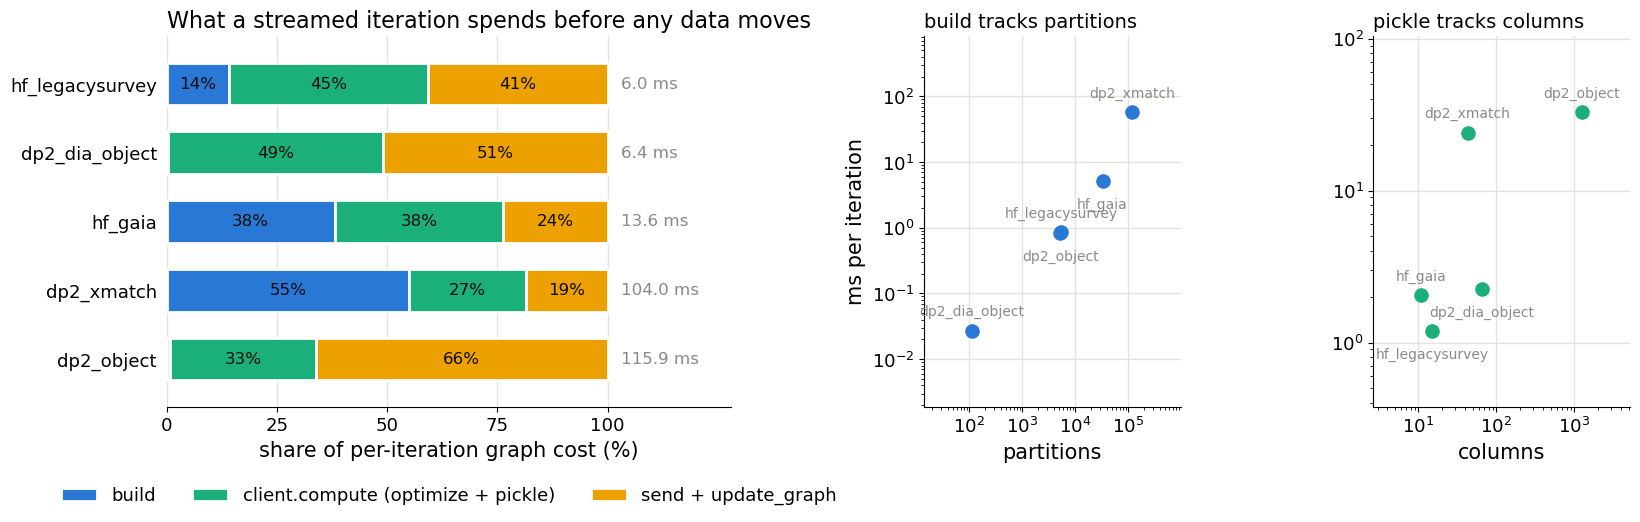

In [15]:
# Palette: slots 1-4 of the ordering already gated for this project in stream-hf-profile.ipynb.
# (The dataviz validator needs `node`, which these hosts do not have, so the ordering is
# reused rather than re-derived.)
SERIES = {
    "build_1px_ms":      ("#2a78d6", "build"),
    "client_compute_ms": ("#1baf7a", "client.compute (optimize + pickle)"),
    "update_graph_ms":   ("#eda100", "send + update_graph"),
}
GRAY, INK = "#8a8a85", "#0b0b0b"

plot_df = b.sort_values("total_ms")
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 5.4), width_ratios=[2.2, 1, 1])
y = np.arange(len(plot_df))[::-1]

# Left: composition. Share, not ms -- absolute cost spans ~20x across these configs, so a
# shared linear axis would crush the cheap rows into slivers. Absolute ms is direct-labelled.
pct = 100 * plot_df[PHASES].div(plot_df["total_ms"], axis=0)
left = np.zeros(len(plot_df))
for key, (color, label) in SERIES.items():
    vals = pct[key].to_numpy()
    ax1.barh(y, vals, left=left, height=0.62, color=color, label=label,
             edgecolor="white", linewidth=2)          # 2px surface gap between segments
    for yi, v, l in zip(y, vals, left):
        if v > 8:                                     # direct-label only segments that fit
            ax1.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=12, color=INK)
    left += vals

for yi, t in zip(y, plot_df["total_ms"]):
    ax1.text(103, yi, f"{t:,.1f} ms", va="center", fontsize=12, color=GRAY)
ax1.set_xlim(0, 128)
ax1.set_ylim(-0.7, len(plot_df) - 0.3)
ax1.set_xticks([0, 25, 50, 75, 100])
ax1.set_yticks(y, plot_df.index)
ax1.set_xlabel("share of per-iteration graph cost (%)")
ax1.set_title("What a streamed iteration spends before any data moves", loc="left")
ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.grid(axis="x", color="#e2e2de", linewidth=1)
ax1.set_axisbelow(True)
ax1.tick_params(left=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False, ncols=3)

# Right: the two axes get one panel each, because "partitions" and "columns" are different
# quantities and must not share a scale. One series apiece, so the title names it -- no legend.
def _scatter(ax, x, yv, color, title, xlabel):
    ax.scatter(x, yv, s=90, color=color, zorder=3)
    # Alternate the label above/below: some configs land on nearly the same point
    # (hf_legacysurvey and dp2_object have almost identical partition counts).
    order = np.argsort(np.asarray(x, dtype=float))
    side = {int(idx): (11 if k % 2 == 0 else -20) for k, idx in enumerate(order)}
    for k, (xi, yi, name) in enumerate(zip(x, yv, plot_df.index)):
        ax.annotate(name, (xi, yi), textcoords="offset points", xytext=(0, side[k]),
                    ha="center", fontsize=10, color=GRAY)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontsize=14)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e2e2de", linewidth=1)
    ax.set_axisbelow(True)
    ax.margins(y=0.35, x=0.30)

_scatter(ax2, plot_df["npartitions"], plot_df["build_1px_ms"],
         SERIES["build_1px_ms"][0], "build tracks partitions", "partitions")
ax2.set_ylabel("ms per iteration")
_scatter(ax3, plot_df["ncolumns"], plot_df["pickle_ms"],
         SERIES["client_compute_ms"][0], "pickle tracks columns", "columns")

fig.tight_layout()
fig.savefig("reports/graph-cost.png", dpi=140, bbox_inches="tight")
plt.show()

## 5. What a pre-computed graph would buy

Both halves exist because the graph is rebuilt and re-shipped every iteration, even though
almost all of it is identical every time. Three counterfactuals, each measured rather than
asserted.

### (a) Build once, index thereafter

In [16]:
pre = budget[["npartitions", "full_build_s", "epoch_build_s", "vs_full_build"]].copy()
pre["epoch_build_h"] = pre["epoch_build_s"] / 3600
pre.sort_values("vs_full_build").round(3)

,npartitions,full_build_s,epoch_build_s,vs_full_build,epoch_build_h
config,,,,,
dp2_dia_object,114,0.000,0.003,6.543,0.000
dp2_object,5244,0.027,4.392,163.972,0.001
hf_legacysurvey,5488,0.024,4.693,196.026,0.001
hf_gaia,33055,0.444,170.804,384.955,0.047
dp2_xmatch,121551,4.559,6945.503,1523.514,1.929


### (b) Ship the constants once

`meta` and `schema` are identical on every submit. The floor is what remains once they are not
in the payload — measured by rebuilding the operation out-of-tree with `verify_meta=False`
(which drops the `meta`-capturing closure) and with `schema=None`. This is a *bound*, not a
proposed patch: real code would scatter them once and reference the futures.

In [17]:
floor_rows = []
for name in ["dp2_object", "dp2_dia_object", "hf_gaia"]:
    op = catalogs[name]._operation
    kw = dict(op.kwargs)
    variants = {
        "as shipped": op,
        "no meta in closure": FromHealpixMap(op.func, op.pixels, *op.args, meta=op._meta,
                                             verify_meta=False, **kw),
        "no meta, no schema": FromHealpixMap(op.func, op.pixels, *op.args, meta=op._meta,
                                             verify_meta=False, **{**kw, "schema": None}),
    }
    for label, o in variants.items():
        warm(o)
        _, p_ms, nbytes = pickle_stats(to_delayed(o, [o.healpix_pixels[0]]))
        floor_rows.append({"config": name, "variant": label,
                           "pickle_ms": p_ms, "payload_b": nbytes})

floor_df = pd.DataFrame(floor_rows).set_index(["config", "variant"])
floor_df["payload_reduction"] = floor_df.groupby(level=0)["payload_b"].transform("max") / floor_df["payload_b"]
floor_df.round(3)

pickle_ms  payload_b  payload_reduction
config         variant                                                    
dp2_object     as shipped             33.587     227209              1.000
               no meta in closure      2.463      56340              4.033
               no meta, no schema      0.048        953            238.414
dp2_dia_object as shipped              2.058      15127              1.000
               no meta in closure      0.201       3682              4.108
               no meta, no schema      0.051        957             15.807
hf_gaia        as shipped              2.129      17599              1.000
               no meta in closure      0.252       4296              4.097
               no meta, no schema      0.065        998             17.634

### (c) Batch the submits

From §2: the payload is near-constant in `partitions_per_chunk`, so bytes-per-task falls almost
linearly with it. Unlike (a) and (b) this needs no code change at all — only a larger
`partitions_per_chunk`, bounded by how much memory a chunk takes.

In [18]:
ppc_saved = pd.read_csv("reports/graph-cost-ppc.csv")
piv = ppc_saved.pivot(index="ppc", columns="config", values="b_per_task")
(piv / piv.loc[1]).round(3)   # bytes per task, relative to ppc=1

config,dp2_dia_object,dp2_object,hf_gaia
ppc,,,
1,1.000,1.000,1.000
2,0.517,0.501,0.517
4,0.268,0.251,0.266
8,0.144,0.126,0.141


### What it would cost to hold the graph

Pre-computing is not free — the full graph has to live somewhere.

In [19]:
import gc
import tracemalloc

hold = []
for name in ["dp2_dia_object", "dp2_object", "dp2_xmatch"]:
    op = warm(catalogs[name]._operation)
    gc.collect()
    # sys.getsizeof on the dict counts only the container, not the Task objects inside it,
    # so measure the allocation directly.
    tracemalloc.start()
    g = op.build()
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    hold.append({"config": name, "nodes": len(g.graph),
                 "dict_only_mb": sys.getsizeof(g.graph) / 1e6,
                 "resident_mb": current / 1e6, "peak_mb": peak / 1e6,
                 "kb_per_node": current / len(g.graph) / 1e3})
    del g
    gc.collect()

hold_df = pd.DataFrame(hold).set_index("config")
print("cost of holding the whole graph in the client process (tracemalloc):")
hold_df.round(2)

cost of holding the whole graph in the client process (tracemalloc):


,nodes,dict_only_mb,resident_mb,peak_mb,kb_per_node
config,,,,,
dp2_dia_object,114,0.00,0.12,0.12,1.05
dp2_object,5244,0.15,5.47,5.47,1.04
dp2_xmatch,370614,20.97,365.98,446.00,0.99


## Findings

*Measured on the run recorded in `reports/graph-cost.csv`. Byte counts are deterministic;
millisecond figures move with machine load, so the ratios are the durable part.*

### 1. Serialization is the larger cost in four of five configs — build wins only for the crossmatch

| config | partitions | columns | build | serialize | build/serialize |
|---|---|---|---|---|---|
| `dp2_dia_object` | 114 | 65 | 0.03 ms | 6.37 ms | 0.004 |
| `dp2_object` | 5,244 | 1,260 | 0.84 ms | 115.1 ms | 0.007 |
| `hf_legacysurvey` | 5,488 | 15 | 0.86 ms | 5.17 ms | 0.166 |
| `hf_gaia` | 33,055 | 11 | 5.17 ms | 8.39 ms | 0.616 |
| `dp2_xmatch` | 121,551 | 43 | **57.14 ms** | 46.82 ms | **1.220** |

The two halves genuinely scale on different axes — `build` tracks partition count and ignores
schema; pickling tracks schema width and ignores partition count. But on *absolute*
per-iteration cost, serialization is the bigger term everywhere except the crossmatch, and even
there it is only narrowly beaten.

The practical reading: **if you are streaming a wide catalog, the cost is serialization. If you
are streaming a crossmatch, it is both, and the iteration costs over 100 ms before any data
moves.**

### 2. Timing `client.compute()` understates the submit path by 1.6-3.0x

`client.compute()` returns once the pickle is enqueued; the send and `Scheduler.update_graph`
land afterwards. For `dp2_object`, `client.compute()` measures 38.4 ms while the scheduler
spends a further **76.6 ms** in `update_graph` — twice the client-side half it follows.

The driver is deserialization, not scheduling: repeating the measurement with two workers
instead of zero changed `update_graph` by at most a factor of two, and for the widest catalog
not at all (`workers_multiple` 0.94 for `dp2_object`, 1.03 and 1.96 for the other two). The
unpickle runs **inline on the scheduler's event loop**, so this blocks the one loop that is also
scheduling everything else on the cluster.

### 3. Two-thirds to 99% of every payload is the same constant bytes, every iteration

`constants_pct` runs from 67.8% (`hf_legacysurvey`) to **99.2%** (`dp2_object`) — the empty
`meta` frame plus the pyarrow `schema`, identical on every submit, re-pickled every time.
`meta` rides along because `build` wraps each task in a fresh `_verified` closure that captures
it, so nothing can cache it across iterations.

Removing them (§5b) takes `dp2_object` from 227,209 B to **953 B — 238x fewer** — and pickling
from 33.6 ms to 0.048 ms.

For the crossmatch, the constants live on the *input* operations beneath `AlignAndApply`
(43,998 B of metas plus 129,501 B of `catalog_infos`), which is why a naive look at only the
outermost operation understates it badly.

### 4. Raising `partitions_per_chunk` is free mitigation, available today

Total payload per submit is near-flat in `partitions_per_chunk` — 227,209 B at ppc=1 versus
229,458 B at ppc=8 for `dp2_object` — because pickle memoizes the shared `meta` and `schema`
within a single call. Bytes per task therefore falls to **0.126x** at ppc=8, close to the ideal
`1/ppc`. This needs no code change, only enough memory to hold a larger chunk.

### 5. `build` is an epoch-scale latency problem, and pre-computing is affordable

`build` never dominates *wall time* against data movement, but it is `O(npartitions)` per layer
and it repeats every iteration:

| config | build once | one pixel at a time, whole epoch | ratio |
|---|---|---|---|
| `hf_gaia` | 0.44 s | 170.8 s | 385x |
| `dp2_xmatch` | 4.56 s | **6,946 s (1.93 hours)** | **1,524x** |

The mechanism is confirmed exactly: 661,140 `HealpixPixel.__hash__` calls against a predicted
`20 builds x 33,055 pixels = 661,100`, all of it rejecting pixels the caller asked to skip.

Holding the pre-built graph is cheap: ~1 kB per node, so **366 MB** resident (446 MB peak) for
the crossmatch's 370,614-node graph, and 5.5 MB for `dp2_object`. A real cost, but not a
prohibitive one against nearly two hours of rebuild.

### 6. A one-line defect blocks the obvious workflow

`SelectPixels.build` raises on any proper-subset build, so a cone- or box-searched catalog
cannot be streamed at all — it raises on `iter()`. Line 413 sets `selected_pixels = self.pixels`
where it needs `effective`, the intersection computed two lines above.

### Speculation: what to change, in what order

1. **Fix `SelectPixels.build`.** One line, and it unblocks spatial-filter-then-stream entirely.
2. **Raise `partitions_per_chunk`** in streaming guidance — free today, no merge required,
   ~8x fewer bytes per task at ppc=8.
3. **Stop re-shipping the constants.** Hoist `_verified` out of the build loop and memoize it,
   then scatter `meta` and `schema` once and reference the futures. This is the biggest single
   win: up to 238x on payload, and it attacks the cost that dominates four of the five configs.
   It also shrinks the scheduler-side half, which is the larger of the two and is invisible to
   any timer around `client.compute()`.
4. **Make `build(pixels=...)` `O(len(pixels))`** — cache `{pixel: index}` on the `Operation`
   (its pixel list is immutable) and look up directly instead of scanning and rejecting. Matters
   for the crossmatch, where it is two hours per epoch, and for anyone doing real epochs over a
   large catalog.

(3) and (4) address different configs; the range measured here needs both. None of them are
implemented here — this notebook measures only.